# Image Viewer — フラット images/ フォルダのビューワー

`font2dataset` 出力形式（`images/` + `metadata.parquet`）の画像を閲覧するためのノートブック。

- **文字（codepoint）ごと**にグリッド表示
- フォントファミリー・文字でフィルタリング可能
- 実フォント・生成フォント・誘導サンプルに対応

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np

# ============================================================
# 設定（ここを変更して使う）
# ============================================================
# DATA_DIR = Path("data/datasets/font2dataset_ascii_google")
DATA_DIR = Path("results/2026-05-20_diffusion_H/checkpoints/last")

FILTER_CHARS  = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")  # 表示する文字（空リストで全文字）
FILTER_FAMILY = ""       # フォントファミリー名の部分一致フィルタ（空文字で全て）
MAX_PER_CHAR  = 20       # 1文字あたり最大表示枚数
COLS          = 10       # グリッドの列数
IMG_SIZE      = 1.2      # 1セルのインチサイズ
# ============================================================

images_dir = DATA_DIR / "images"
meta_path  = DATA_DIR / "metadata.parquet"

meta = pd.read_parquet(meta_path)
print(f"Total rows : {len(meta):,}")
print(f"Chars      : {sorted(meta['char'].unique())}")
print(f"Families   : {meta['font_family'].nunique()} families")
meta.head(3)

Total rows : 2,631
Chars      : ['H']
Families   : 1 families


,file,char,unicode,codepoint,font_path,font_family,font_style,sampling_timesteps,cond_scale,realness_score
0,0048_generated_st50_cs1.0_000000.png,H,U+0048,72,models...,generated,st50_cs1.0,50,1.0,0.993141
1,0048_generated_st50_cs1.0_000001.png,H,U+0048,72,models...,generated,st50_cs1.0,50,1.0,0.248518
2,0048_generated_st50_cs1.0_000002.png,H,U+0048,72,models...,generated,st50_cs1.0,50,1.0,0.988063


## 文字ごとにグリッド表示

Filtered : 2,631 rows / 1 chars
Score    : mean=0.8182  std=0.3083  min=0.0001  max=0.9959


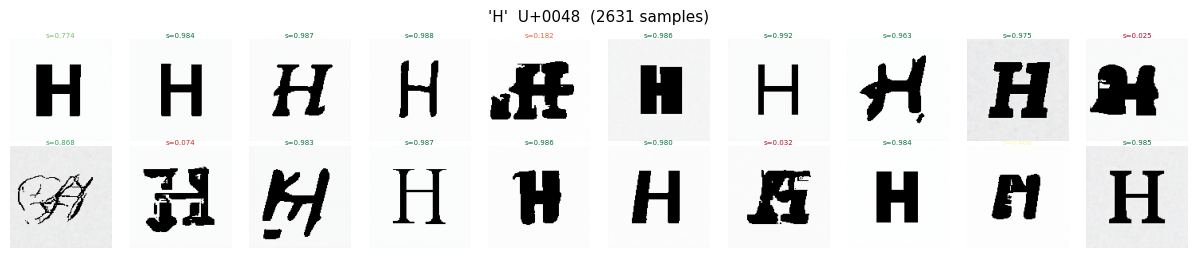

In [2]:
def show_grid(df: pd.DataFrame, title: str, images_dir: Path,
              max_images: int = 20, cols: int = 10, img_size: float = 1.2) -> None:
    """メタデータの行群をグリッド表示する。realness_score 列があれば各画像に表示。"""
    has_score = "realness_score" in df.columns and df["realness_score"].notna().any()
    rows_sample = df.sample(min(max_images, len(df)), random_state=0)
    n = len(rows_sample)
    if n == 0:
        return
    nrows = (n + cols - 1) // cols
    fig, axes = plt.subplots(nrows, cols, figsize=(cols * img_size, nrows * img_size))
    axes = np.array(axes).reshape(-1)
    for ax, (_, row) in zip(axes, rows_sample.iterrows()):
        path = images_dir / row["file"]
        if path.exists():
            ax.imshow(mpimg.imread(str(path)), cmap="gray")
        else:
            ax.text(0.5, 0.5, "N/A", ha="center", va="center", fontsize=6)
        if has_score and pd.notna(row.get("realness_score")):
            label = f"s={row['realness_score']:.3f}"
            color = plt.cm.RdYlGn(float(row["realness_score"]))
            ax.set_title(label, fontsize=5, pad=1, color=color)
        else:
            label = str(row.get("font_style", row.get("font_family", "")))[:12]
            ax.set_title(label, fontsize=5, pad=1)
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle(title, fontsize=11, y=1.01)
    fig.tight_layout(pad=0.3)
    plt.show()


# --- フィルタ適用 ---
view = meta.copy()
if FILTER_CHARS:
    view = view[view["char"].isin(FILTER_CHARS)]
if FILTER_FAMILY:
    view = view[view["font_family"].str.contains(FILTER_FAMILY, case=False, na=False)]

print(f"Filtered : {len(view):,} rows / {view['char'].nunique()} chars")
if "realness_score" in view.columns:
    print(f"Score    : mean={view['realness_score'].mean():.4f}  "
          f"std={view['realness_score'].std():.4f}  "
          f"min={view['realness_score'].min():.4f}  "
          f"max={view['realness_score'].max():.4f}")

# --- 文字ごとに描画 ---
for char, group in view.groupby("char", sort=True):
    cp = ord(char)
    show_grid(
        group,
        title=f"'{char}'  U+{cp:04X}  ({len(group)} samples)",
        images_dir=images_dir,
        max_images=MAX_PER_CHAR,
        cols=COLS,
        img_size=IMG_SIZE,
    )

## 実フォント vs 生成フォントの並列比較

同じ文字について実フォントと生成フォントを並べて表示する。

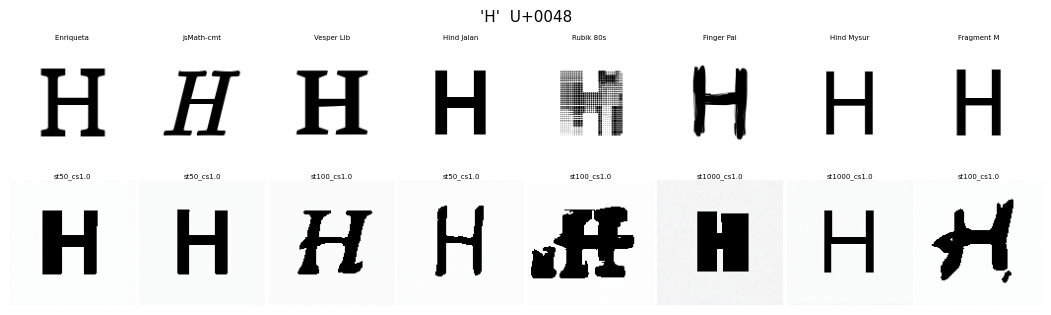

In [3]:
REAL_DIR = Path("data/datasets/font2dataset_ascii_google")
GEN_DIR  = Path("results/2026-05-20_diffusion_H/checkpoints/last")
COMPARE_CHARS = list("H")   # 比較したい文字
N_EACH = 8                      # 実/生成それぞれ何枚表示するか

real_meta = pd.read_parquet(REAL_DIR / "metadata.parquet")
gen_meta  = pd.read_parquet(GEN_DIR  / "metadata.parquet")

for char in COMPARE_CHARS:
    real_rows = real_meta[real_meta["char"] == char].sample(
        min(N_EACH, len(real_meta[real_meta["char"] == char])), random_state=0
    )
    gen_rows = gen_meta[gen_meta["char"] == char].sample(
        min(N_EACH, len(gen_meta[gen_meta["char"] == char])), random_state=0
    )

    fig, axes = plt.subplots(2, N_EACH, figsize=(N_EACH * 1.3, 3.2))

    for col, (_, row) in enumerate(real_rows.iterrows()):
        p = REAL_DIR / "images" / row["file"]
        axes[0, col].imshow(mpimg.imread(str(p)), cmap="gray")
        axes[0, col].set_title(row["font_family"][:10], fontsize=5, pad=1)
        axes[0, col].axis("off")

    for col, (_, row) in enumerate(gen_rows.iterrows()):
        p = GEN_DIR / "images" / row["file"]
        axes[1, col].imshow(mpimg.imread(str(p)), cmap="gray")
        style = row.get("font_style", "")
        axes[1, col].set_title(style[:12], fontsize=5, pad=1)
        axes[1, col].axis("off")

    for col in range(len(real_rows), N_EACH):
        axes[0, col].axis("off")
    for col in range(len(gen_rows), N_EACH):
        axes[1, col].axis("off")

    axes[0, 0].set_ylabel("Real", fontsize=8, rotation=0, labelpad=30, va="center")
    axes[1, 0].set_ylabel("Gen",  fontsize=8, rotation=0, labelpad=30, va="center")
    fig.suptitle(f"'{char}'  U+{ord(char):04X}", fontsize=11)
    fig.tight_layout(pad=0.3)
    plt.show()

## Realness Score 分布

`realness_score` 列がある場合に条件ごとの分布を可視化する。

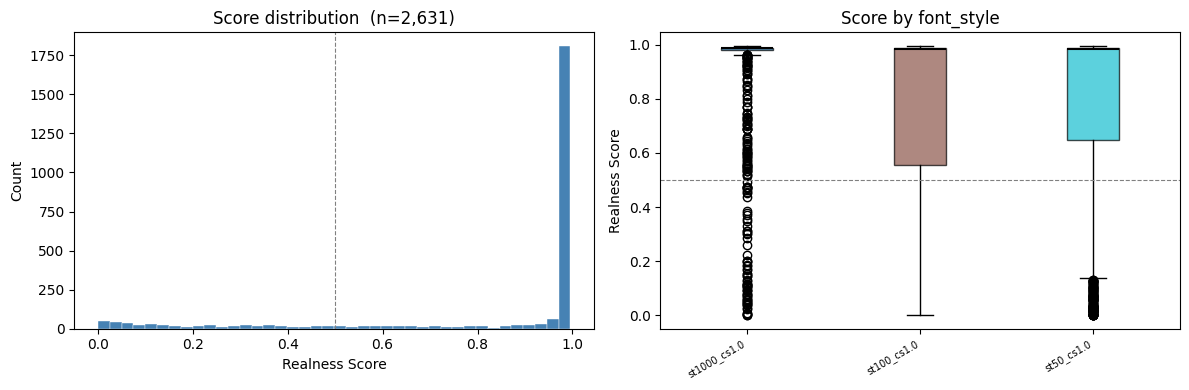

,n,mean,std,min,max
font_style,,,,,
st1000_cs1.0,877,0.9001,0.2261,0.0005,0.9947
st100_cs1.0,877,0.7750,0.3278,0.0003,0.9959
st50_cs1.0,877,0.7794,0.3417,0.0001,0.9940


In [5]:
SCORE_DIR = Path("results/2026-05-20_diffusion_H/checkpoints/last")
# SCORE_DIR = Path("data/datasets/font2dataset_ascii_google")
# グループ化する列（存在する列のみ使用）
GROUP_BY = "font_style"   # "cond_scale" / "sampling_timesteps" / "font_style" など

score_meta = pd.read_parquet(SCORE_DIR / "metadata.parquet")

if "realness_score" not in score_meta.columns or score_meta["realness_score"].isna().all():
    print("realness_score 列がありません。score_images.py または generate_fonts.py --scorer を先に実行してください。")
else:
    score_meta = score_meta.dropna(subset=["realness_score"])

    # --- ヒストグラム（全体） ---
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].hist(score_meta["realness_score"], bins=40, color="steelblue", edgecolor="white", linewidth=0.3)
    axes[0].axvline(0.5, color="gray", linestyle="--", linewidth=0.8)
    axes[0].set_xlabel("Realness Score")
    axes[0].set_ylabel("Count")
    axes[0].set_title(f"Score distribution  (n={len(score_meta):,})")

    # --- 条件ごとの箱ひげ図 ---
    if GROUP_BY in score_meta.columns:
        groups = sorted(score_meta[GROUP_BY].unique())
        data = [score_meta.loc[score_meta[GROUP_BY] == g, "realness_score"].values for g in groups]
        bp = axes[1].boxplot(data, patch_artist=True, medianprops=dict(color="black", linewidth=1.5))
        colors = plt.cm.tab10(np.linspace(0, 1, len(groups)))
        for patch, color in zip(bp["boxes"], colors):
            patch.set_facecolor(color)
            patch.set_alpha(0.7)
        axes[1].set_xticks(range(1, len(groups) + 1))
        axes[1].set_xticklabels(groups, rotation=30, ha="right", fontsize=7)
        axes[1].axhline(0.5, color="gray", linestyle="--", linewidth=0.8)
        axes[1].set_ylabel("Realness Score")
        axes[1].set_title(f"Score by {GROUP_BY}")
    else:
        axes[1].axis("off")
        axes[1].text(0.5, 0.5, f"'{GROUP_BY}' 列なし", ha="center", va="center")

    fig.tight_layout()
    plt.show()

    # --- 数値サマリ ---
    if GROUP_BY in score_meta.columns:
        summary = score_meta.groupby(GROUP_BY)["realness_score"].agg(["count","mean","std","min","max"])
        summary.columns = ["n", "mean", "std", "min", "max"]
        display(summary.round(4))

## Score Top-N / Bottom-N

Realness Score が高い画像・低い画像をランキング表示する。

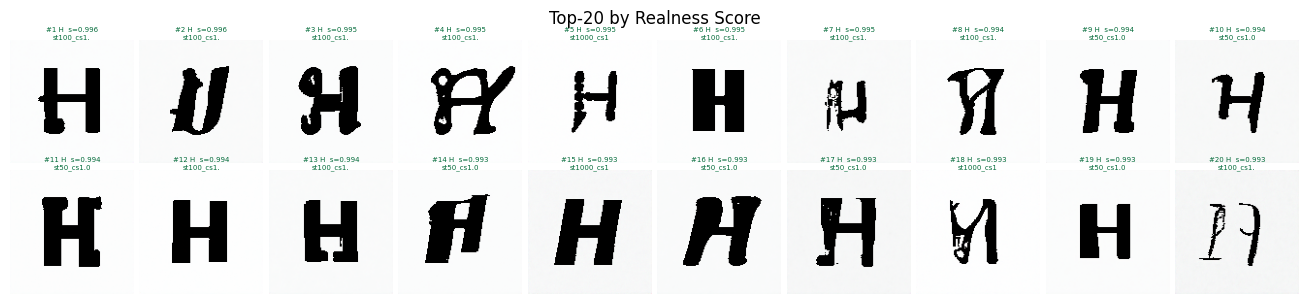

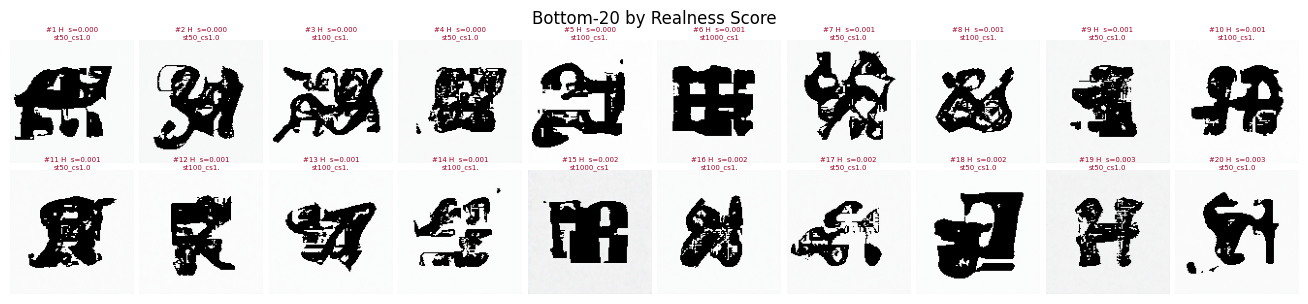

In [7]:
TOPN_DIR         = Path("results/2026-05-20_diffusion_H/checkpoints/last")
# TOPN_DIR = Path("data/datasets/font2dataset_ascii_google")
TOPN_N           = 20       # 上位・下位それぞれ何枚表示するか
TOPN_COLS        = 10       # グリッドの列数
TOPN_FILTER_CHAR = ""       # 特定の文字に絞る場合は "A" など（空文字で全文字）

topn_meta = pd.read_parquet(TOPN_DIR / "metadata.parquet")
topn_images_dir = TOPN_DIR / "images"

if "realness_score" not in topn_meta.columns or topn_meta["realness_score"].isna().all():
    print("realness_score 列がありません。score_images.py または generate_fonts.py --scorer を先に実行してください。")
else:
    topn_meta = topn_meta.dropna(subset=["realness_score"])
    if TOPN_FILTER_CHAR:
        topn_meta = topn_meta[topn_meta["char"] == TOPN_FILTER_CHAR]

    def show_ranked(df: pd.DataFrame, images_dir: Path, n: int, cols: int, high: bool) -> None:
        ranked = df.nlargest(n, "realness_score") if high else df.nsmallest(n, "realness_score")
        label = "Top" if high else "Bottom"
        nrows = (len(ranked) + cols - 1) // cols
        fig, axes = plt.subplots(nrows, cols, figsize=(cols * 1.3, nrows * 1.5))
        axes = np.array(axes).reshape(-1)
        for rank, (ax, (_, row)) in enumerate(zip(axes, ranked.iterrows()), start=1):
            path = images_dir / row["file"]
            if path.exists():
                ax.imshow(mpimg.imread(str(path)), cmap="gray")
            else:
                ax.text(0.5, 0.5, "N/A", ha="center", va="center", fontsize=6)
            score = row["realness_score"]
            char  = row.get("char", "")
            style = str(row.get("font_style", ""))[:10]
            ax.set_title(
                f"#{rank} {char}  s={score:.3f}\n{style}",
                fontsize=5, pad=1,
                color=plt.cm.RdYlGn(float(score)),
            )
            ax.axis("off")
        for ax in axes[len(ranked):]:
            ax.axis("off")
        char_info = f" — '{TOPN_FILTER_CHAR}'" if TOPN_FILTER_CHAR else ""
        fig.suptitle(f"{label}-{n} by Realness Score{char_info}", fontsize=12)
        fig.tight_layout(pad=0.4)
        plt.show()

    show_ranked(topn_meta, topn_images_dir, n=TOPN_N, cols=TOPN_COLS, high=True)
    show_ranked(topn_meta, topn_images_dir, n=TOPN_N, cols=TOPN_COLS, high=False)

## Guided Sample — realness_scale による制御の確認

`realness_scale` を変えると Realness Score が連続的に変化するかを可視化する。

realness_scales: [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0)]  |  total: 40 images  |  has_score: True


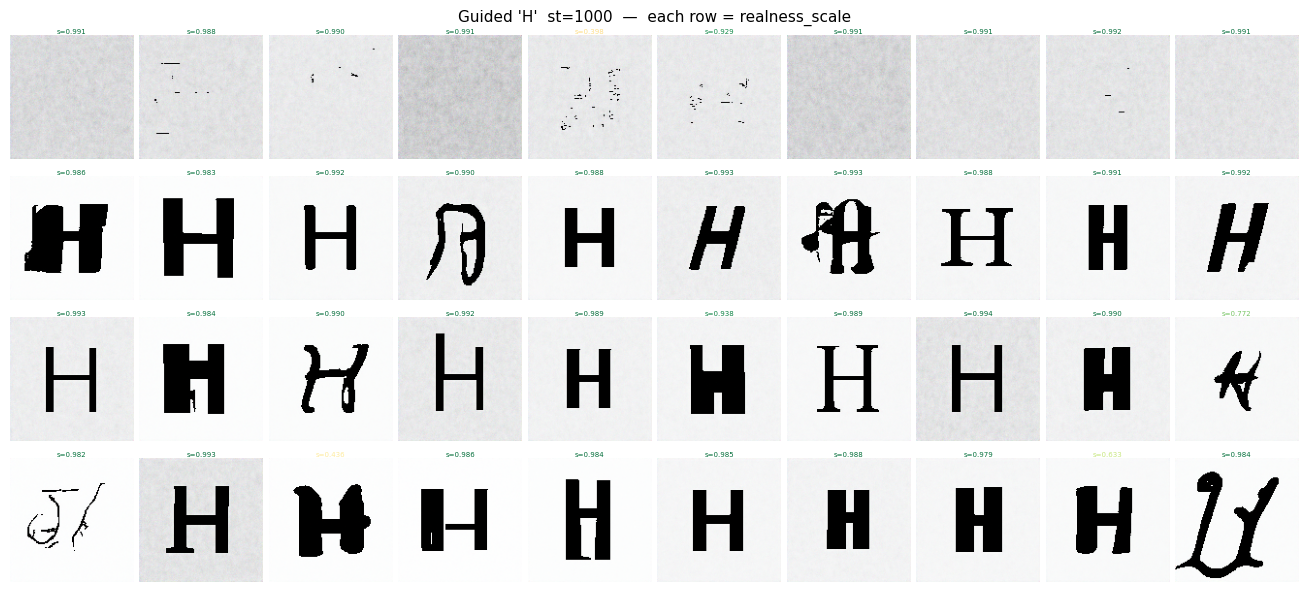

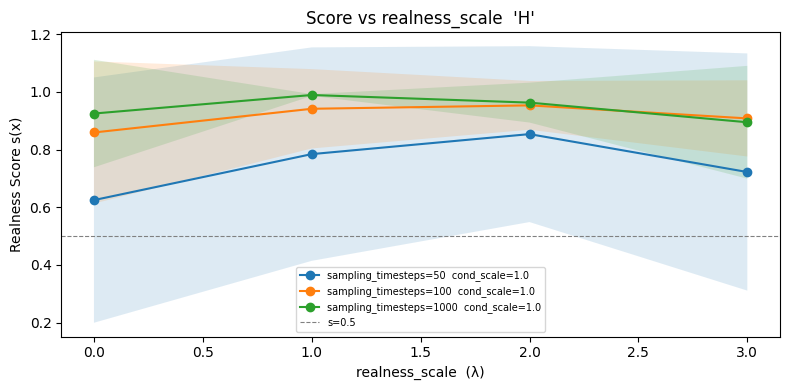

In [8]:
GUIDED_DIR   = Path("results/guided/2026-05-21_scorer_H/checkpoints/last")
GUIDED_CHAR  = "H"       # 表示する文字（1文字）
FIX_COND_SCALE         = None    # 固定する cond_scale（None で全て）
FIX_SAMPLING_TIMESTEPS = 1000     # 固定する sampling_timesteps（None で全て）
N_PER_SCALE  = 10        # realness_scale ごとに表示する枚数

guided_meta = pd.read_parquet(GUIDED_DIR / "metadata.parquet")
guided_images_dir = GUIDED_DIR / "images"

has_score = "realness_score" in guided_meta.columns

# --- フィルタ ---
gv = guided_meta[guided_meta["char"] == GUIDED_CHAR].copy()
if FIX_COND_SCALE is not None and "cond_scale" in gv.columns:
    gv = gv[gv["cond_scale"] == FIX_COND_SCALE]
if FIX_SAMPLING_TIMESTEPS is not None and "sampling_timesteps" in gv.columns:
    gv = gv[gv["sampling_timesteps"] == FIX_SAMPLING_TIMESTEPS]

scales = sorted(gv["realness_scale"].unique())
print(f"realness_scales: {scales}  |  total: {len(gv)} images  |  has_score: {has_score}")

# ============================================================
# 1. realness_scale ごとに画像グリッド（横1行ずつ）
# ============================================================
fig, axes = plt.subplots(
    len(scales), N_PER_SCALE,
    figsize=(N_PER_SCALE * 1.3, len(scales) * 1.5),
)
if len(scales) == 1:
    axes = axes[np.newaxis, :]

for row_idx, scale in enumerate(scales):
    subset = gv[gv["realness_scale"] == scale].sample(
        min(N_PER_SCALE, len(gv[gv["realness_scale"] == scale])), random_state=0
    )
    for col_idx in range(N_PER_SCALE):
        ax = axes[row_idx, col_idx]
        if col_idx < len(subset):
            img_row = subset.iloc[col_idx]
            p = guided_images_dir / img_row["file"]
            if p.exists():
                ax.imshow(mpimg.imread(str(p)), cmap="gray")
            if has_score and pd.notna(img_row.get("realness_score")):
                s = img_row["realness_score"]
                ax.set_title(f"s={s:.3f}", fontsize=5, pad=1,
                             color=plt.cm.RdYlGn(float(s)))
        ax.axis("off")
    axes[row_idx, 0].set_ylabel(f"rs={scale:+.1f}", fontsize=8,
                                rotation=0, labelpad=40, va="center")

cond_info = f"  cs={FIX_COND_SCALE}" if FIX_COND_SCALE else ""
st_info   = f"  st={FIX_SAMPLING_TIMESTEPS}" if FIX_SAMPLING_TIMESTEPS else ""
fig.suptitle(f"Guided '{GUIDED_CHAR}'{cond_info}{st_info}  —  each row = realness_scale",
             fontsize=11)
fig.tight_layout(pad=0.4)
plt.show()

# ============================================================
# 2. mean score vs realness_scale（条件別ライン）
# ============================================================
if has_score:
    fig2, ax2 = plt.subplots(figsize=(8, 4))

    # cond_scale × sampling_timesteps の組み合わせをラインとして描画
    group_cols = [c for c in ["sampling_timesteps", "cond_scale"] if c in guided_meta.columns]
    plot_data = guided_meta[guided_meta["char"] == GUIDED_CHAR].dropna(subset=["realness_score"])

    if group_cols:
        groups = plot_data.groupby(group_cols + ["realness_scale"])["realness_score"]
        summary = groups.agg(["mean", "std"]).reset_index()

        for keys, grp in summary.groupby(group_cols):
            keys = keys if isinstance(keys, tuple) else (keys,)
            label = "  ".join(f"{c}={v}" for c, v in zip(group_cols, keys))
            grp_sorted = grp.sort_values("realness_scale")
            ax2.plot(grp_sorted["realness_scale"], grp_sorted["mean"], marker="o", label=label)
            ax2.fill_between(
                grp_sorted["realness_scale"],
                grp_sorted["mean"] - grp_sorted["std"],
                grp_sorted["mean"] + grp_sorted["std"],
                alpha=0.15,
            )
    else:
        summary = plot_data.groupby("realness_scale")["realness_score"].agg(["mean","std"]).reset_index()
        ax2.plot(summary["realness_scale"], summary["mean"], marker="o")
        ax2.fill_between(summary["realness_scale"],
                         summary["mean"] - summary["std"],
                         summary["mean"] + summary["std"], alpha=0.15)

    ax2.axhline(0.5, color="gray", linestyle="--", linewidth=0.8, label="s=0.5")
    ax2.set_xlabel("realness_scale  (λ)")
    ax2.set_ylabel("Realness Score s(x)")
    ax2.set_title(f"Score vs realness_scale  '{GUIDED_CHAR}'")
    ax2.legend(fontsize=7)
    fig2.tight_layout()
    plt.show()

## アーティファクト解析 — ピクセル分布 & 周波数解析

実フォントと生成フォントの統計的差異を可視化する。

- **ピクセル値ヒストグラム**: 実フォントは 0/1 の二峰性、生成フォントは中間値（グレー）が多い
- **FFT パワースペクトル**: 実フォントは高周波成分が強い（鋭いエッジ）、生成フォントは低周波寄り

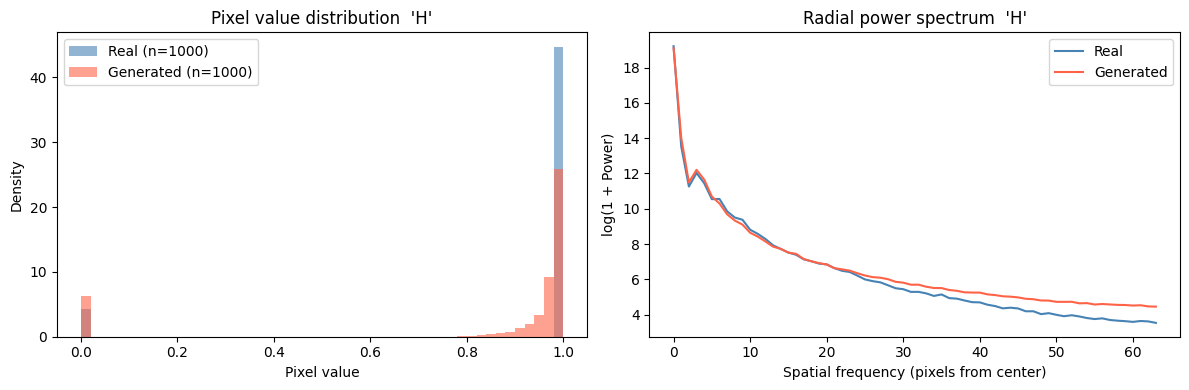

Real      — mean: 0.9039  std: 0.2895  frac<0.1: 0.089  frac>0.9: 0.897
Generated — mean: 0.8498  std: 0.3238  frac<0.1: 0.126  frac>0.9: 0.831


In [9]:
ARTIFACT_REAL_DIR = Path("data/datasets/font2dataset_ascii_google")
ARTIFACT_GEN_DIR  = Path("results/2026-05-20_diffusion_H/checkpoints/last")
ARTIFACT_CHAR     = "H"     # 比較する文字
N_ARTIFACT        = 1000     # 各カテゴリから読み込む枚数

# --- 画像を numpy 配列として読み込む ---
def load_images(meta: pd.DataFrame, images_dir: Path, char: str, n: int) -> np.ndarray:
    rows = meta[meta["char"] == char].sample(min(n, len(meta[meta["char"] == char])), random_state=0)
    imgs = []
    for _, row in rows.iterrows():
        p = images_dir / row["file"]
        if p.exists():
            img = np.array(mpimg.imread(str(p)))
            if img.ndim == 3:
                img = img.mean(axis=2)   # グレースケール化
            imgs.append(img.flatten())
    return np.array(imgs) if imgs else np.empty((0,))

real_meta = pd.read_parquet(ARTIFACT_REAL_DIR / "metadata.parquet")
gen_meta  = pd.read_parquet(ARTIFACT_GEN_DIR  / "metadata.parquet")

real_px = load_images(real_meta, ARTIFACT_REAL_DIR / "images", ARTIFACT_CHAR, N_ARTIFACT)
gen_px  = load_images(gen_meta,  ARTIFACT_GEN_DIR  / "images", ARTIFACT_CHAR, N_ARTIFACT)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# ============================================================
# 1. ピクセル値ヒストグラム
# ============================================================
ax = axes[0]
if real_px.size:
    ax.hist(real_px.flatten(), bins=50, alpha=0.6, color="steelblue",
            label=f"Real (n={len(real_px)})", density=True)
if gen_px.size:
    ax.hist(gen_px.flatten(),  bins=50, alpha=0.6, color="tomato",
            label=f"Generated (n={len(gen_px)})", density=True)
ax.set_xlabel("Pixel value")
ax.set_ylabel("Density")
ax.set_title(f"Pixel value distribution  '{ARTIFACT_CHAR}'")
ax.legend()

# ============================================================
# 2. FFT 平均パワースペクトル（放射方向平均）
# ============================================================
def radial_power_spectrum(images_flat: np.ndarray, h: int, w: int) -> tuple[np.ndarray, np.ndarray]:
    """各画像の FFT パワーを放射方向に平均して返す。"""
    imgs = images_flat.reshape(-1, h, w)
    power_sum = np.zeros((h, w))
    for img in imgs:
        F = np.fft.fftshift(np.fft.fft2(img))
        power_sum += np.abs(F) ** 2
    power_mean = power_sum / len(imgs)

    cy, cx = h // 2, w // 2
    y, x = np.ogrid[:h, :w]
    r = np.sqrt((x - cx) ** 2 + (y - cy) ** 2).astype(int)
    r_max = min(cx, cy)
    radii = np.arange(r_max)
    profile = np.array([power_mean[r == ri].mean() if (r == ri).any() else 0 for ri in radii])
    return radii, profile

ax2 = axes[1]
# 画像サイズを取得
sample_img = np.array(mpimg.imread(str(ARTIFACT_REAL_DIR / "images" / real_meta[real_meta["char"] == ARTIFACT_CHAR].iloc[0]["file"])))
H, W = sample_img.shape[:2]

if real_px.size:
    r, p = radial_power_spectrum(real_px, H, W)
    ax2.plot(r, np.log1p(p), color="steelblue", label="Real")
if gen_px.size:
    r2, p2 = radial_power_spectrum(gen_px, H, W)
    ax2.plot(r2, np.log1p(p2), color="tomato", label="Generated")

ax2.set_xlabel("Spatial frequency (pixels from center)")
ax2.set_ylabel("log(1 + Power)")
ax2.set_title(f"Radial power spectrum  '{ARTIFACT_CHAR}'")
ax2.legend()

fig.tight_layout()
plt.show()

# 数値サマリ
print(f"Real      — mean: {real_px.mean():.4f}  std: {real_px.std():.4f}  " +
      f"frac<0.1: {(real_px<0.1).mean():.3f}  frac>0.9: {(real_px>0.9).mean():.3f}")
print(f"Generated — mean: {gen_px.mean():.4f}  std: {gen_px.std():.4f}  " +
      f"frac<0.1: {(gen_px<0.1).mean():.3f}  frac>0.9: {(gen_px>0.9).mean():.3f}")